In [1]:
import scanpy as sc
import numpy as np
import random
import sys
sys.path.append("../../mapqc/")
import mapqc
import plotting

In [2]:
%load_ext lab_black

### Set paths and parameters

In [3]:
atlas_path = "../../data/HLCA_full_v1.1_emb.h5ad"

metadata key/cat info:

In [4]:
ref_q_key = "core_or_extension"
ref_cat = "core"
query_cat = "extension"
condition_key = "lung_condition"
control_cats = ["Healthy", "Healthy (tumor adjacent)"]
batch_key = "dataset"

parameters:

In [5]:
n_nhoods = 100
k = 1000
min_n_cells_per_sample_per_nhood = 5
min_n_samples_per_nhood_r_or_q = 3
query_condition_of_interest = "Healthy"

### Prepare anndata:

read in full atlas (with all queries)

In [6]:
adata_full = sc.read_h5ad(atlas_path)

#### choose query dataset and query condition of interest and subset data:

list reference batches:

In [7]:
print("Reference batches:")
print(
    sorted(adata_full.obs.loc[adata_full.obs[ref_q_key] == ref_cat, batch_key].unique())
)

Reference batches:
['Banovich_Kropski_2020', 'Barbry_Leroy_2020', 'Jain_Misharin_2021_10Xv1', 'Jain_Misharin_2021_10Xv2', 'Krasnow_2020', 'Lafyatis_Rojas_2019_10Xv1', 'Lafyatis_Rojas_2019_10Xv2', 'Meyer_2019', 'Misharin_2021', 'Misharin_Budinger_2018', 'Nawijn_2021', 'Seibold_2020_10Xv2', 'Seibold_2020_10Xv3', 'Teichmann_Meyer_2019']


list query batches:

In [8]:
print("Query batches:")
print(
    sorted(
        adata_full.obs.loc[adata_full.obs[ref_q_key] == query_cat, batch_key].unique()
    )
)

Query batches:
['Banovich_Kropski_2020', 'Budinger_2020', 'Duong_lungMAP_unpubl', 'Eils_2020', 'Gomperts2021_UCLA', 'Gomperts_2021_CFF', 'Gomperts_2021_CSMC', 'Janssen_2020', 'Kaminski_2020', 'Lafyatis_2019', 'Lambrechts_2021', 'MeyerNikolic_unpubl_UCL', 'Meyer_2021_3prime', 'Meyer_2021_5prime', 'Misharin_Budinger_2018', 'Peer_Massague_2020', 'Regev_2021_Cryo', 'Regev_2021_Fresh', 'Regev_2021_Nuclei', 'Schiller_2020', 'Schiller_2021', 'Schultze_unpubl', 'Shalek_2018', 'Sheppard_2020', 'Sims_2019', 'Sun_2020_batch1', 'Sun_2020_batch2', 'Sun_2020_batch3', 'Sun_2020_batch4', 'Tata_unpubl', 'Thienpont_2018_10Xv1', 'Thienpont_2018_10Xv2', 'Wunderink_2021_cryo', 'Wunderink_2021_fresh', 'Xu_2020_LAM1_3', 'Zhang_2021']


subset to query batch of choice:

In [9]:
query_batch = "Zhang_2021"

In [10]:
adata = adata_full[
    (adata_full.obs[ref_q_key] == ref_cat) | (adata_full.obs[batch_key] == query_batch)
].copy()

If using a reference batch as "simulated" query, annotate it as query here:

In [11]:
if query_batch in (adata.obs.loc[adata.obs[ref_q_key] == ref_cat, batch_key].values):
    print(f"Setting batch {query_batch} to 'query' as query simulation.")
    adata.obs[ref_q_key] = adata.obs[ref_q_key].tolist()
    adata.obs.loc[adata.obs[batch_key] == query_batch, ref_q_key] = query_cat

Some clean-up for the Thienpont_2018 study specifically:

In [12]:
if query_batch in ["Thienpont_2018_10Xv1", "Thienpont_2018_10Xv2"]:
    print("setting Thienpont tumor adjacent samples to 'Healthy'")
    lambrechts_sample_info = pd.read_csv(
        "./lambrechts_health_status_info.csv", index_col=0
    )
    lambrechts_healthy_samples = lambrechts_sample_info.loc[
        ~lambrechts_sample_info.cell_from_tumor, :
    ].index.tolist()
    adata.obs.loc[
        adata.obs["sample"].values.isin(lambrechts_healthy_samples), condition_key
    ] = "Healthy"

check which conditions are in the query:

In [13]:
sorted(adata.obs.loc[adata.obs[batch_key] == query_batch, condition_key].unique())

['COVID-19 moderate', 'COVID-19 severe', 'Healthy']

Subset to specific condition for the query specifically (reference is already fully healthy):

In [14]:
condition_of_interest = "Healthy"

In [15]:
print(f"Subsetting query to condition {condition_of_interest}")
adata = adata[
    (adata.obs[ref_q_key] == ref_cat)
    | (adata.obs[condition_key] == condition_of_interest)
].copy()

Subsetting query to condition Healthy


### Run mapQC

randomly sample neighborhood center cells from query (this should probably be incorporated in the package as well, maybe some "prep_adata" function...)

In [16]:
query_cell_idc = np.where(adata.obs[ref_q_key] == query_cat)[0].tolist()
random.seed(0)
center_cell_idc = random.sample(query_cell_idc, k=n_nhoods)
center_cells = np.array(adata.obs.iloc[center_cell_idc, :].index)

create mapqc results instance:

In [17]:
results = mapqc.mapQC_results(
    adata=adata,
    center_cells=center_cells,
    k=k,
    ref_q_key="core_or_extension",
    ref_cat="core",
    query_cat="extension",
)

calculate sample distances to ref samples:

In [18]:
results.calculate_sample_dists_to_ref_samples()

../../mapqc/mapqc.py:107: RuntimeWarning: Mean of empty slice
  self.mean_sample_dists_to_ref = np.nanmean(self.intersample_distances, axis=0)


calculate stats on distances:

In [19]:
results.calculate_nhood_statistics()

14% of neighborhoods passed filtering.
93% of neighborhoods that passed filtering are below the significance threshold alpha=0.05.


plot results:

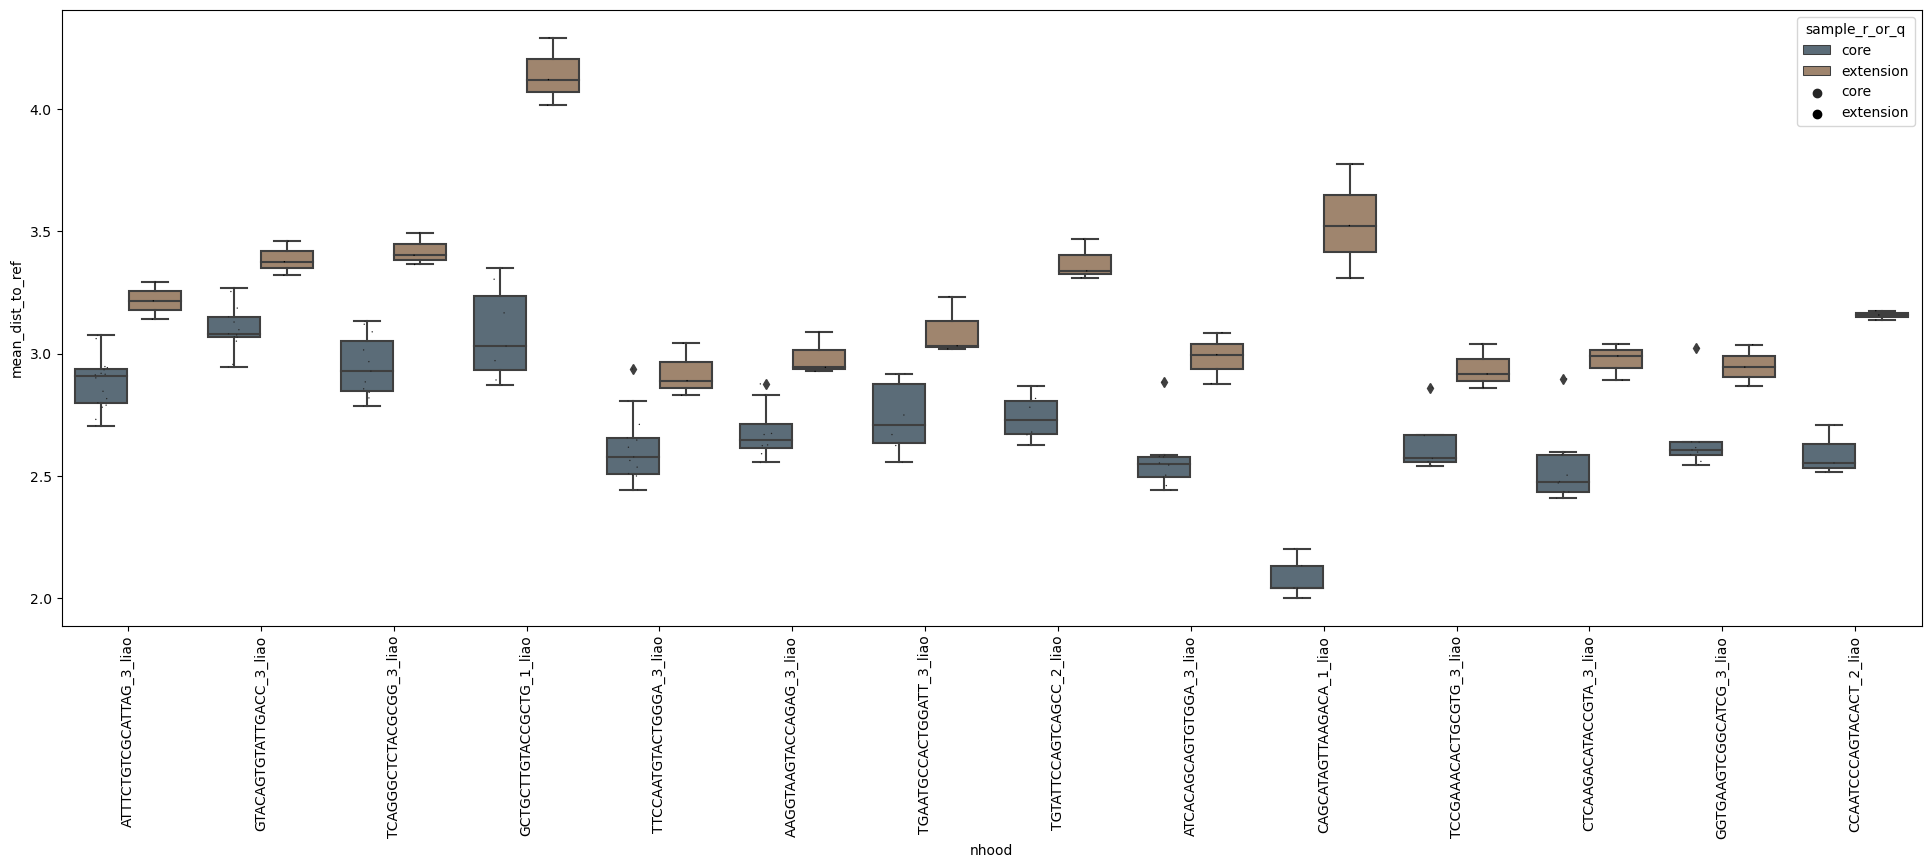

In [20]:
plotting.plot_ref_vs_q_dists_per_nhood(results)

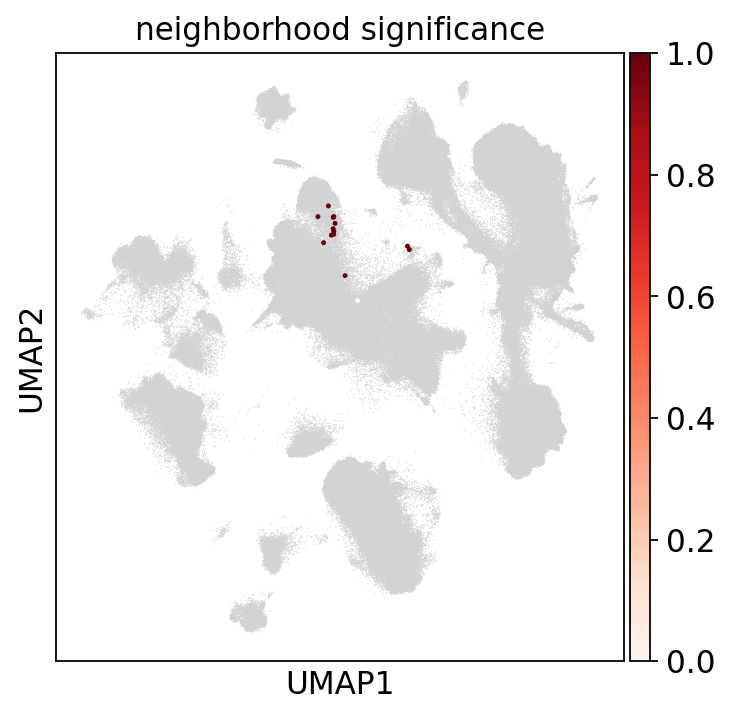

In [21]:
plotting.plot_umap_significance(results)